# Chaos Weekends? Weather at Formula 1 Race Weekends by Circuit Climate

**Derek Galperin**
**November 15, 2026**

*Data Analysis Report: Python, pandas, matplotlib & statsmodels*

## Part 1: Selecting and Exploring the Dataset

### Introducing the dataset

**Dataset:** Historical daily weather from the **Open-Meteo Historical Weather API**
([open-meteo.com/en/docs/historical-weather-api](https://open-meteo.com/en/docs/historical-weather-api)).
Race dates come from the official Formula 1
calendars for 2022–2025 ([formula1.com](https://www.formula1.com/en/racing)).

**Why I chose it:** With alll of my photographw work,  my long-term goal is to shoot Formula 1.
Weather shapes a race weekend more than almost anything else: it decides tire strategy and whether a race
turns chaotic, and it decides what I'd need to pack and how I'd protect my gear. Fans and commentators
often say that "tropical" races like Singapore, Miami and São Paulo are the wild, rain-soaked ones. I wanted
to check whether the data backs that up.

**What each observation represents:** Each row is **one day of a race weekend at one circuit**, using the
Friday, Saturday and race day of each event. I collected 9 circuits × 4 seasons (2022–2025) × 3 days, which gives
**108 observations**.

The circuits are grouped into three climate zones:

| Climate zone | Circuits |
|---|---|
| Desert | Bahrain, Jeddah, Abu Dhabi |
| European (temperate) | Silverstone, Spa-Francorchamps, Monza |
| Tropical | Singapore, Miami, São Paulo (Interlagos) |

**Variables I plan to investigate:**

- `precip_mm` (quantitative): total precipitation for the day, in millimetres
- `temp_mean_c` (quantitative): mean air temperature for the day, °C
- `humidity_pct` (quantitative): mean relative humidity for the day, %
- `cloud_pct`, `wind_max_kmh` and `precip_hours` (quantitative): supporting variables
- `climate_zone` (categorical, created by me): Desert / European / Tropical

### Research question and hypothesis

**Research question:** Are F1 race weekends at tropical circuits hotter and wetter than race weekends at
temperate European circuits?

**Hypothesis:** Tropical race weekends will be **both hotter and rainier** than European race weekends.
Specifically, I expect tropical circuits to have a higher mean daily temperature and more daily
precipitation. Desert circuits are included as a dry baseline for comparison.

### This assignment was heavily assisted by Claude Opus 5.5 with guideance by myself. The code was run by Claude but all analysis was by me. ###

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

*Note:* Bahrain and Jeddah held their 2024 races on a Saturday, so their "weekend" ends on Saturday.

In [2]:
DATA_PATH = "data/f1_raceweekend_weather_raw.json"

# circuit: (latitude, longitude, {season: race date})
CIRCUITS = {
    "Bahrain":     (26.0325, 50.5106,  {2022: "2022-03-20", 2023: "2023-03-05", 2024: "2024-03-02", 2025: "2025-04-13"}),
    "Jeddah":      (21.6319, 39.1044,  {2022: "2022-03-27", 2023: "2023-03-19", 2024: "2024-03-09", 2025: "2025-04-20"}),
    "Abu Dhabi":   (24.4672, 54.6031,  {2022: "2022-11-20", 2023: "2023-11-26", 2024: "2024-12-08", 2025: "2025-12-07"}),
    "Silverstone": (52.0786, -1.0169,  {2022: "2022-07-03", 2023: "2023-07-09", 2024: "2024-07-07", 2025: "2025-07-06"}),
    "Spa":         (50.4372, 5.9714,   {2022: "2022-08-28", 2023: "2023-07-30", 2024: "2024-07-28", 2025: "2025-07-27"}),
    "Monza":       (45.6156, 9.2811,   {2022: "2022-09-11", 2023: "2023-09-03", 2024: "2024-09-01", 2025: "2025-09-07"}),
    "Singapore":   (1.2914, 103.8640,  {2022: "2022-10-02", 2023: "2023-09-17", 2024: "2024-09-22", 2025: "2025-10-05"}),
    "Miami":       (25.9581, -80.2389, {2022: "2022-05-08", 2023: "2023-05-07", 2024: "2024-05-05", 2025: "2025-05-04"}),
    "Sao Paulo":   (-23.7036, -46.6997,{2022: "2022-11-13", 2023: "2023-11-05", 2024: "2024-11-03", 2025: "2025-11-09"}),
}

DAILY_VARS = ("temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,"
              "precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,cloud_cover_mean")


def download_raceweekend_weather(path):
    # Request Friday -> race day for every circuit/season and save the raw responses as one JSON file.
    import time
    import requests

    records = []
    for circuit, (lat, lon, races) in CIRCUITS.items():
        for season, race_day in races.items():
            start = (pd.Timestamp(race_day) - pd.Timedelta(days=2)).strftime("%Y-%m-%d")
            params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": race_day,
                      "daily": DAILY_VARS, "timezone": "auto"}
            resp = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=30)
            resp.raise_for_status()
            d = resp.json()
            records.append({"circuit": circuit, "season": season, "race_date": race_day,
                            "latitude": d["latitude"], "longitude": d["longitude"],
                            "elevation": d["elevation"], "timezone": d["timezone"], "daily": d["daily"]})
            time.sleep(0.2)  # be polite to the free API
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w") as f:
        json.dump(records, f)


if not os.path.exists(DATA_PATH):
    download_raceweekend_weather(DATA_PATH)

with open(DATA_PATH) as f:
    raw = json.load(f)

print(f"Loaded {len(raw)} circuit-season records from {DATA_PATH}")
print(json.dumps(raw[0], indent=2)[:900])

Loaded 36 circuit-season records from data/f1_raceweekend_weather_raw.json
{
  "circuit": "Bahrain",
  "season": 2022,
  "race_date": "2022-03-20",
  "latitude": 26.045692,
  "longitude": 50.514225,
  "elevation": 8,
  "timezone": "Asia/Bahrain",
  "daily": {
    "time": [
      "2022-03-18",
      "2022-03-19",
      "2022-03-20"
    ],
    "temperature_2m_max": [
      20.1,
      22.9,
      28.5
    ],
    "temperature_2m_min": [
      14.7,
      14.1,
      14.5
    ],
    "temperature_2m_mean": [
      17,
      18.1,
      20.5
    ],
    "precipitation_sum": [
      0,
      0,
      0
    ],
    "precipitation_hours": [
      0,
      0,
      0
    ],
    "relative_humidity_2m_mean": [
      50,
      52,
      45
    ],
    "wind_speed_10m_max": [
      36.9,
      32.6,
      26
    ],
    "cloud_cover_mean": [
      0,
      0,
      0
    ]
  }
}


In [3]:
df = pd.json_normalize(raw)                       # columns like 'daily.time', 'daily.precipitation_sum' (lists)
list_cols = [c for c in df.columns if c.startswith("daily.")]
df = df.explode(list_cols, ignore_index=True)     # one row per day
df.columns = [c.replace("daily.", "") for c in df.columns]

df.head()

,circuit,season,race_date,latitude,longitude,elevation,timezone,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,cloud_cover_mean
0,Bahrain,2022,2022-03-20,26.045692,50.514225,8,Asia/Bahrain,2022-03-18,20.1,14.7,17,0,0,50,36.9,0
1,Bahrain,2022,2022-03-20,26.045692,50.514225,8,Asia/Bahrain,2022-03-19,22.9,14.1,18.1,0,0,52,32.6,0
2,Bahrain,2022,2022-03-20,26.045692,50.514225,8,Asia/Bahrain,2022-03-20,28.5,14.5,20.5,0,0,45,26,0
3,Bahrain,2023,2023-03-05,26.045692,50.514225,8,Asia/Bahrain,2023-03-03,26.9,13.9,20.3,0,0,54,19.1,0
4,Bahrain,2023,2023-03-05,26.045692,50.514225,8,Asia/Bahrain,2023-03-04,29.9,15.2,22.2,0,0,50,16.7,0


### Examining structure and data types

In [4]:
print("Shape:", df.shape)
print()
df.info()

Shape: (108, 16)

<class 'pandas.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   circuit                    108 non-null    str    
 1   season                     108 non-null    int64  
 2   race_date                  108 non-null    str    
 3   latitude                   108 non-null    float64
 4   longitude                  108 non-null    float64
 5   elevation                  108 non-null    int64  
 6   timezone                   108 non-null    str    
 7   time                       108 non-null    str    
 8   temperature_2m_max         108 non-null    object 
 9   temperature_2m_min         108 non-null    object 
 10  temperature_2m_mean        108 non-null    object 
 11  precipitation_sum          108 non-null    object 
 12  precipitation_hours        108 non-null    object 
 13  relative_humidity_2m_mean  108 non-null    

`explode()` leaves every weather column as an `object` (text-like) type, and the dates are still strings. Before
I can analyze anything, those need to become proper numbers and dates.

### Cleaning and transforming

Changes Claude made to the original data:

1. **Renamed columns** to short names with units (`precipitation_sum` → `precip_mm`, etc.) so the code and charts are easier to read.
2. **Converted data types:** weather values become numeric, and `date` and `race_date` become datetimes.
3. **Created `climate_zone`**, a new categorical variable that groups each circuit into Desert / European / Tropical.
4. **Created `weekend_day`** (Day 1 / Day 2 / Race day) from how many days each row falls before the race.
5. **Created `wet_day`**, which is `True` when precipitation is at least 1 mm. That's the standard meteorological threshold for a "wet day", and it filters out trace drizzle.
6. **Dropped columns** I don't need for the analysis (`latitude`, `longitude`, `timezone`).
7. **Checked for missing values and duplicate rows.**

In [5]:
df = df.rename(columns={
    "time": "date",
    "temperature_2m_max": "temp_max_c",
    "temperature_2m_min": "temp_min_c",
    "temperature_2m_mean": "temp_mean_c",
    "precipitation_sum": "precip_mm",
    "precipitation_hours": "precip_hours",
    "relative_humidity_2m_mean": "humidity_pct",
    "wind_speed_10m_max": "wind_max_kmh",
    "cloud_cover_mean": "cloud_pct",
})

weather_cols = ["temp_max_c", "temp_min_c", "temp_mean_c", "precip_mm", "precip_hours",
                "humidity_pct", "wind_max_kmh", "cloud_pct"]
df[weather_cols] = df[weather_cols].apply(pd.to_numeric)
df["date"] = pd.to_datetime(df["date"])
df["race_date"] = pd.to_datetime(df["race_date"])

# New categorical variable: climate zone
ZONE_OF = {
    "Bahrain": "Desert", "Jeddah": "Desert", "Abu Dhabi": "Desert",
    "Silverstone": "European", "Spa": "European", "Monza": "European",
    "Singapore": "Tropical", "Miami": "Tropical", "Sao Paulo": "Tropical",
}
ZONES = ["Desert", "European", "Tropical"]
df["climate_zone"] = pd.Categorical(df["circuit"].map(ZONE_OF), categories=ZONES)

# New variables: day of the race weekend, and wet day flag
days_before = (df["race_date"] - df["date"]).dt.days
df["weekend_day"] = days_before.map({2: "Day 1", 1: "Day 2", 0: "Race day"})
df["wet_day"] = df["precip_mm"] >= 1.0

df = df.drop(columns=["latitude", "longitude", "timezone"])

print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nObservations per climate zone:")
print(df["climate_zone"].value_counts().sort_index().to_string())

Missing values per column:
circuit         0
season          0
race_date       0
elevation       0
date            0
temp_max_c      0
temp_min_c      0
temp_mean_c     0
precip_mm       0
precip_hours    0
humidity_pct    0
wind_max_kmh    0
cloud_pct       0
climate_zone    0
weekend_day     0
wet_day         0

Duplicate rows: 0

Observations per climate zone:
climate_zone
Desert      36
European    36
Tropical    36


There are no missing values and no duplicates, and each climate zone has exactly 36 days (3 circuits × 4 seasons × 3 days),
so the groups are balanced. Here is the cleaned DataFrame and its new data types:

In [6]:
print(df.dtypes)
df.head()

circuit                    str
season                   int64
race_date       datetime64[us]
elevation                int64
date            datetime64[us]
temp_max_c             float64
temp_min_c             float64
temp_mean_c            float64
precip_mm              float64
precip_hours             int64
humidity_pct             int64
wind_max_kmh           float64
cloud_pct                int64
climate_zone          category
weekend_day                str
wet_day                   bool
dtype: object


,circuit,season,race_date,elevation,date,temp_max_c,temp_min_c,temp_mean_c,precip_mm,precip_hours,humidity_pct,wind_max_kmh,cloud_pct,climate_zone,weekend_day,wet_day
0,Bahrain,2022,2022-03-20,8,2022-03-18,20.1,14.7,17.0,0.0,0,50,36.9,0,Desert,Day 1,False
1,Bahrain,2022,2022-03-20,8,2022-03-19,22.9,14.1,18.1,0.0,0,52,32.6,0,Desert,Day 2,False
2,Bahrain,2022,2022-03-20,8,2022-03-20,28.5,14.5,20.5,0.0,0,45,26.0,0,Desert,Race day,False
3,Bahrain,2023,2023-03-05,8,2023-03-03,26.9,13.9,20.3,0.0,0,54,19.1,0,Desert,Day 1,False
4,Bahrain,2023,2023-03-05,8,2023-03-04,29.9,15.2,22.2,0.0,0,50,16.7,0,Desert,Day 2,False


In [7]:
df[weather_cols].describe().round(1)

,temp_max_c,temp_min_c,temp_mean_c,precip_mm,precip_hours,humidity_pct,wind_max_kmh,cloud_pct
count,108.0,108.0,108.0,108.0,108.0,108.0,108.0,108.0
mean,26.6,18.1,22.1,2.7,4.2,70.5,19.7,47.8
std,4.9,4.6,4.5,5.1,5.6,13.0,7.5,35.4
min,15.1,8.9,12.5,0.0,0.0,37.0,5.4,0.0
25%,22.2,14.5,18.3,0.0,0.0,60.0,13.9,15.8
50%,28.1,17.2,22.4,0.2,1.5,74.0,19.0,50.0
75%,30.1,21.6,25.5,2.1,7.0,80.0,23.7,82.0
max,37.5,27.2,30.5,21.3,23.0,94.0,42.6,100.0


One detail stands out already: the **median daily precipitation is only 0.2 mm, while the mean is 2.7 mm**.
That means a few very wet days are pulling the average up, and most days are dry or nearly dry. The
histogram in Part 2 shows this more clearly.

A quick summary by climate zone:

In [8]:
zone_summary = df.groupby("climate_zone", observed=True).agg(
    mean_temp_c=("temp_mean_c", "mean"),
    mean_humidity_pct=("humidity_pct", "mean"),
    mean_precip_mm=("precip_mm", "mean"),
    median_precip_mm=("precip_mm", "median"),
    pct_wet_days=("wet_day", "mean"),
)
zone_summary["pct_wet_days"] *= 100
zone_summary.round(1)

,mean_temp_c,mean_humidity_pct,mean_precip_mm,median_precip_mm,pct_wet_days
climate_zone,,,,,
Desert,23.8,56.9,0.0,0.0,0.0
European,18.3,76.2,4.5,1.0,50.0
Tropical,24.2,78.4,3.6,1.8,58.3


## Part 2: Exploring the Data with Visualizations


### 4. Histogram: distribution of daily precipitation

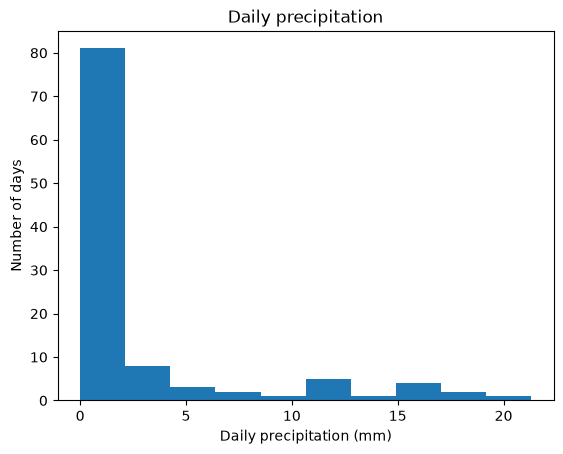

In [9]:
plt.hist(df["precip_mm"])
plt.xlabel("Daily precipitation (mm)")
plt.ylabel("Number of days")
plt.title("Daily precipitation")
plt.show()

To see how the number of bins changes the picture, I plotted the same variable with 5, 10 and 30 bins:

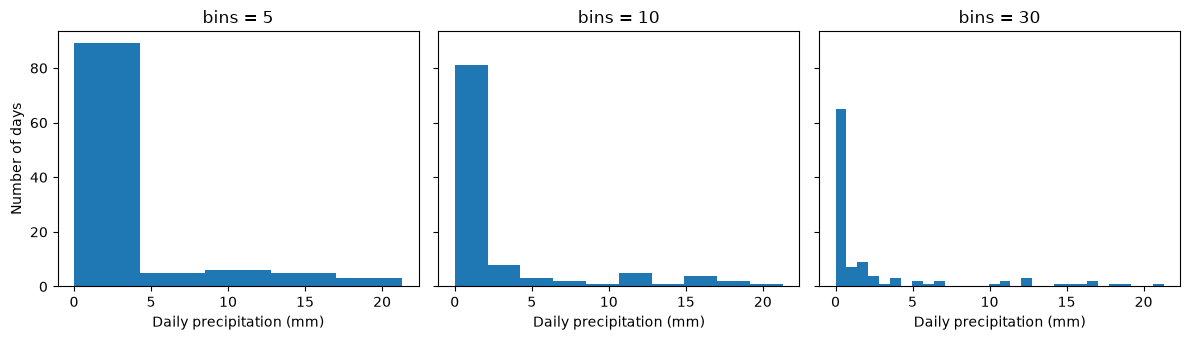

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, b in zip(axes, [5, 10, 30]):
    ax.hist(df["precip_mm"], bins=b)
    ax.set_title(f"bins = {b}")
    ax.set_xlabel("Daily precipitation (mm)")
axes[0].set_ylabel("Number of days")
plt.tight_layout()
plt.show()

**What does the distribution look like?** It's **strongly right-skewed**. Most race-weekend days had little or no rain, and
the counts drop off quickly as precipitation increases. There's a long tail out to about 21 mm.

**Are there any unusual values or patterns?** Two things. First, there's a big pile of exactly-zero values: **50 of the
108 days (46%) had no precipitation at all**, and 69 days had less than 1 mm. Every desert day sits in that zero spike.
Second, a handful of extreme wet days make up the tail. The wettest was Saturday at **Spa in 2023 (21.3 mm)**, followed by race day at
Monza 2024 (19.1 mm) and race day at São Paulo 2024 (17.9 mm). These aren't errors; they're exactly the "chaos" days
I'm interested in.

**How does the choice of bins affect the visualization?** With **5 bins**, everything from 0 to about 4 mm falls into one
bar, which hides the fact that most of those days were completely dry. **10 bins** (the default) shows the skew but
still lumps dry days together with drizzle days. **30 bins** separates the zero spike clearly and shows the gaps in
the tail, but the bars get noisy and many bins are empty. For the final version I use bins that are exactly 1 mm wide, so
each bar has a clear meaning ("days with 0–1 mm", "1–2 mm", and so on).

### 5. Scatter plot: temperature vs. humidity, by climate zone

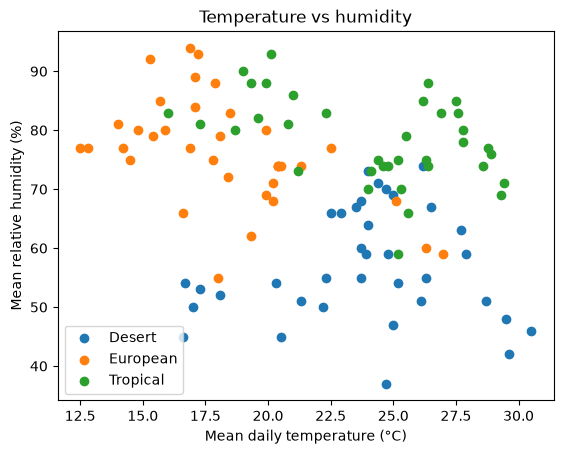

In [11]:
for zone in ZONES:
    subset = df[df["climate_zone"] == zone]
    plt.scatter(subset["temp_mean_c"], subset["humidity_pct"], label=zone)
plt.xlabel("Mean daily temperature (°C)")
plt.ylabel("Mean relative humidity (%)")
plt.title("Temperature vs humidity")
plt.legend()
plt.show()

**Patterns and relationships:** The points form **three fairly distinct clusters**, one for each climate zone.

- **Desert** days are warm (mean of about 24 °C) but much drier in the air (around 57% humidity). They fill the lower-right part of the plot.
- **European** days are the coolest (about 18 °C) and quite humid (about 76%). They sit in the upper-left.
- **Tropical** days are warm *and* humid (about 24 °C and 78%), in the upper-right. They're the only group that is high on both axes.

Across all 108 days, temperature and humidity have a weak *negative* correlation (r ≈ −0.31), but that overall number
is misleading because it mostly reflects the differences *between* zones. Coloring the points by zone shows that
climate zone, not temperature alone, explains where a circuit lands. It also shows that **tropical and desert circuits
are about equally hot**. What sets the tropical circuits apart is the humidity.

### 6. Boxplot: daily precipitation by climate zone

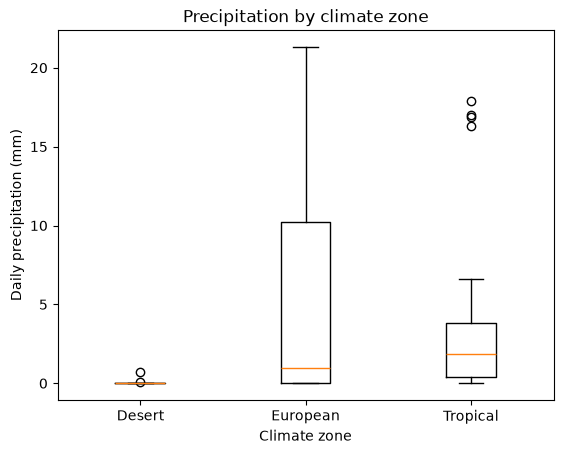

In [12]:
data_by_zone = [df.loc[df["climate_zone"] == z, "precip_mm"] for z in ZONES]
plt.boxplot(data_by_zone)
plt.xticks([1, 2, 3], ZONES)
plt.xlabel("Climate zone")
plt.ylabel("Daily precipitation (mm)")
plt.title("Precipitation by climate zone")
plt.show()

**What the boxplot reveals:**

- **Desert:** Almost no rain at all. The box is flattened at 0 mm. Only two of the 36 desert days recorded any
  precipitation (0.1 mm and 0.7 mm), and those show up as tiny outlier dots.
- **Tropical:** The **median is the highest of the three (1.85 mm)**, and the box is fairly *narrow* (IQR of about 0.4–3.8 mm).
  Tropical weekends tend to get *some* rain on most days, but usually not much. The wettest tropical days (Singapore 2022,
  Miami 2022, São Paulo 2024) appear as outliers above the whisker.
- **European:** The median is lower (0.95 mm), but the box is much *taller* (IQR of about 0–10.3 mm), and the whisker reaches past 20 mm.
  European weekends are more "all or nothing": many days are completely dry, but when it rains, it pours.

So the boxplot already complicates my hypothesis. Tropical circuits get rain **more often**, but European circuits
get the **heaviest** rain.

## Part 3: Improving the Visualizations

### 7. Intentional design choices

Before redesigning, I set up a few things that apply to **every** final figure, so the report has one consistent
visual style:

- A style sheet (`seaborn-v0_8-whitegrid`) for a clean, light background
- One **color per climate zone** that means the same thing in every figure. Sand/orange is **Desert**, cool blue is
  **European**, and teal is **Tropical**. The colors are meant to suggest each climate, so readers can remember the key without
  checking the legend.
- **F1 red** (`#E10600`) reserved for reference lines and highlights, so anything red means "look here."
- A shared helper function that removes the top/right borders and lightens the gridlines on every chart.

In [13]:
style = "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
plt.style.use(style)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "legend.fontsize": 10,
})

ZONE_COLORS = {"Desert": "#D98E04", "European": "#3B6EA8", "Tropical": "#1A9E77"}
ZONE_MARKERS = {"Desert": "s", "European": "o", "Tropical": "^"}
F1_RED = "#E10600"
GREY = "#555555"


def clean_axes(ax, grid_axis="y"):
    # Shared styling: drop top/right spines and use light dashed gridlines on one axis only.
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#999999")
    ax.grid(False)
    ax.grid(axis=grid_axis, color="#DDDDDD", linestyle="--", linewidth=0.8)
    ax.set_axisbelow(True)

#### Final Figure 1: Histogram

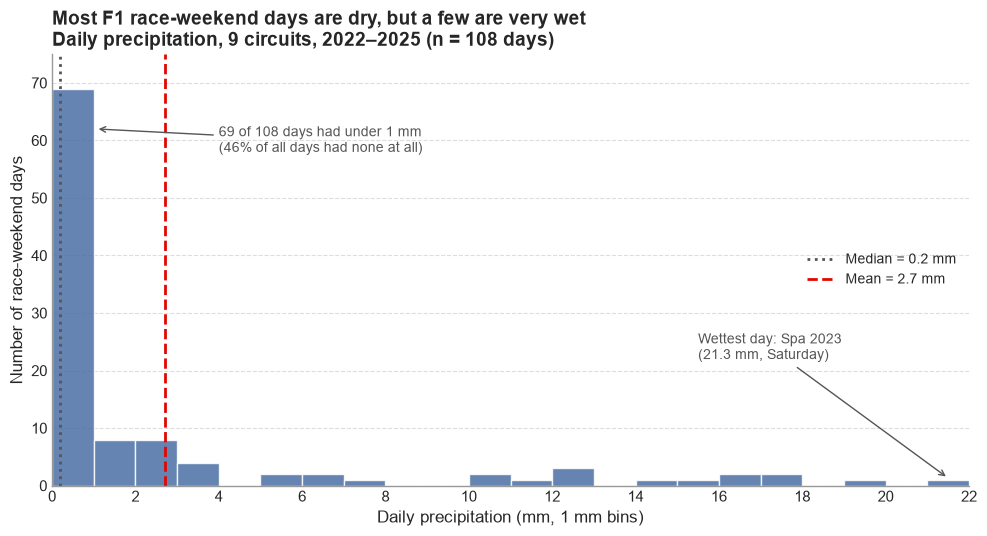

In [14]:
precip = df["precip_mm"]
mean_p, median_p = precip.mean(), precip.median()
dry_share = (precip == 0).mean() * 100

plt.figure(figsize=(10, 5.5))
plt.hist(precip, bins=np.arange(0, 23, 1), color="#4A6FA5", alpha=0.85, edgecolor="white", linewidth=1)

plt.axvline(median_p, color=GREY, linestyle=":", linewidth=2, label=f"Median = {median_p:.1f} mm")
plt.axvline(mean_p, color=F1_RED, linestyle="--", linewidth=2, label=f"Mean = {mean_p:.1f} mm")

ax = plt.gca()
clean_axes(ax)
wettest = df.loc[precip.idxmax()]
plt.annotate(f"Wettest day: {wettest['circuit']} {wettest['season']}\n({wettest['precip_mm']:.1f} mm, Saturday)",
             xy=(wettest["precip_mm"] + 0.2, 1.3), xytext=(15.5, 22),
             arrowprops=dict(arrowstyle="->", color=GREY), fontsize=10, color=GREY)
under1 = (precip < 1).sum()
plt.annotate(f"{under1} of {len(precip)} days had under 1 mm\n({dry_share:.0f}% of all days had none at all)",
             xy=(1.05, 62), xytext=(4, 58), fontsize=10, color=GREY,
             arrowprops=dict(arrowstyle="->", color=GREY))

plt.xlim(0, 22)
plt.xticks(range(0, 23, 2))
plt.ylim(0, 75)
plt.title("Most F1 race-weekend days are dry, but a few are very wet\n"
          "Daily precipitation, 9 circuits, 2022–2025 (n = 108 days)", loc="left")
plt.xlabel("Daily precipitation (mm, 1 mm bins)")
plt.ylabel("Number of race-weekend days")
plt.legend(frameon=False, loc="center right")
plt.tight_layout()
plt.show()

#### Final Figure 2: Scatter plot

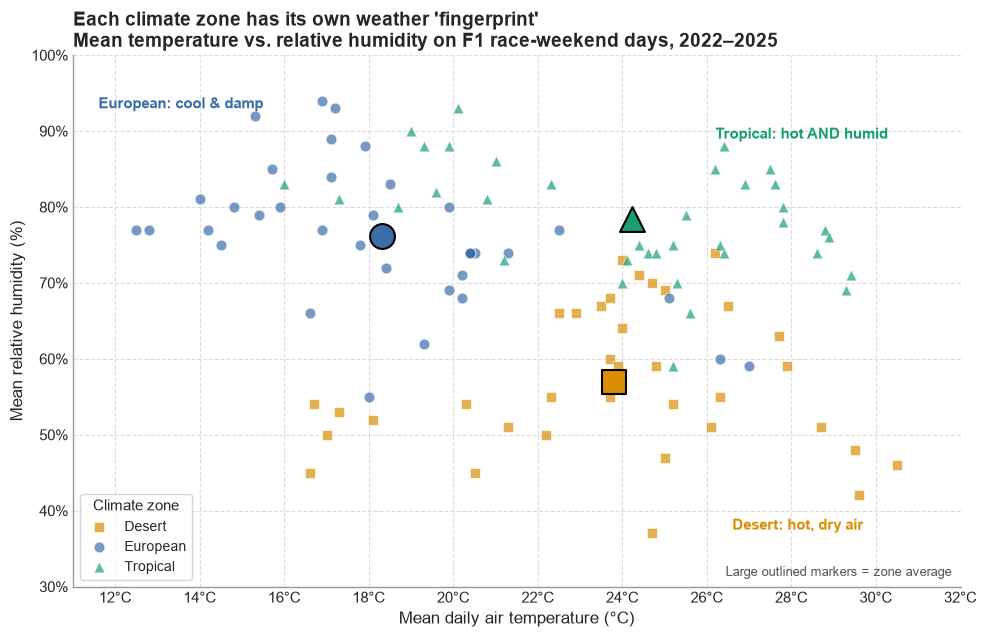

In [15]:
fig, ax = plt.subplots(figsize=(10, 6.5))
plt.sca(ax)
for zone in ZONES:
    s = df[df["climate_zone"] == zone]
    plt.scatter(s["temp_mean_c"], s["humidity_pct"], label=zone,
                color=ZONE_COLORS[zone], marker=ZONE_MARKERS[zone],
                s=60, alpha=0.7, edgecolor="white", linewidth=0.6)
    # Zone average shown as a large outlined marker
    plt.scatter(s["temp_mean_c"].mean(), s["humidity_pct"].mean(),
                color=ZONE_COLORS[zone], marker=ZONE_MARKERS[zone],
                s=320, edgecolor="black", linewidth=1.5, zorder=5)

clean_axes(ax, grid_axis="both")

ax.annotate("Desert: hot, dry air", xy=(26.6, 37.5), fontsize=11, color=ZONE_COLORS["Desert"], fontweight="bold")
ax.annotate("European: cool & damp", xy=(11.6, 93), fontsize=11, color=ZONE_COLORS["European"], fontweight="bold")
ax.annotate("Tropical: hot AND humid", xy=(26.2, 89), fontsize=11, color=ZONE_COLORS["Tropical"], fontweight="bold")
ax.text(0.99, 0.02, "Large outlined markers = zone average", transform=ax.transAxes,
        ha="right", fontsize=9, color=GREY)

plt.xlim(11, 32)
plt.ylim(30, 100)
ax.set_xticks(range(12, 33, 2))
ax.set_yticks(range(30, 101, 10))
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0f}%")
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:.0f}°C")
plt.title("Each climate zone has its own weather 'fingerprint'\n"
          "Mean temperature vs. relative humidity on F1 race-weekend days, 2022–2025", loc="left")
plt.xlabel("Mean daily air temperature (°C)")
plt.ylabel("Mean relative humidity (%)")
plt.legend(title="Climate zone", frameon=True, loc="lower left")
plt.tight_layout()
plt.show()

#### Final Figure 3: Boxplots (subplots)

For the final boxplot, I put **precipitation and temperature side by side** using subplots. My hypothesis makes two claims
(hotter *and* wetter), so showing both variables together lets readers check each one at a glance. I also
overlay the individual days as faint dots, because rain data has so many zeros that the box alone can hide how
the data is actually spread out.

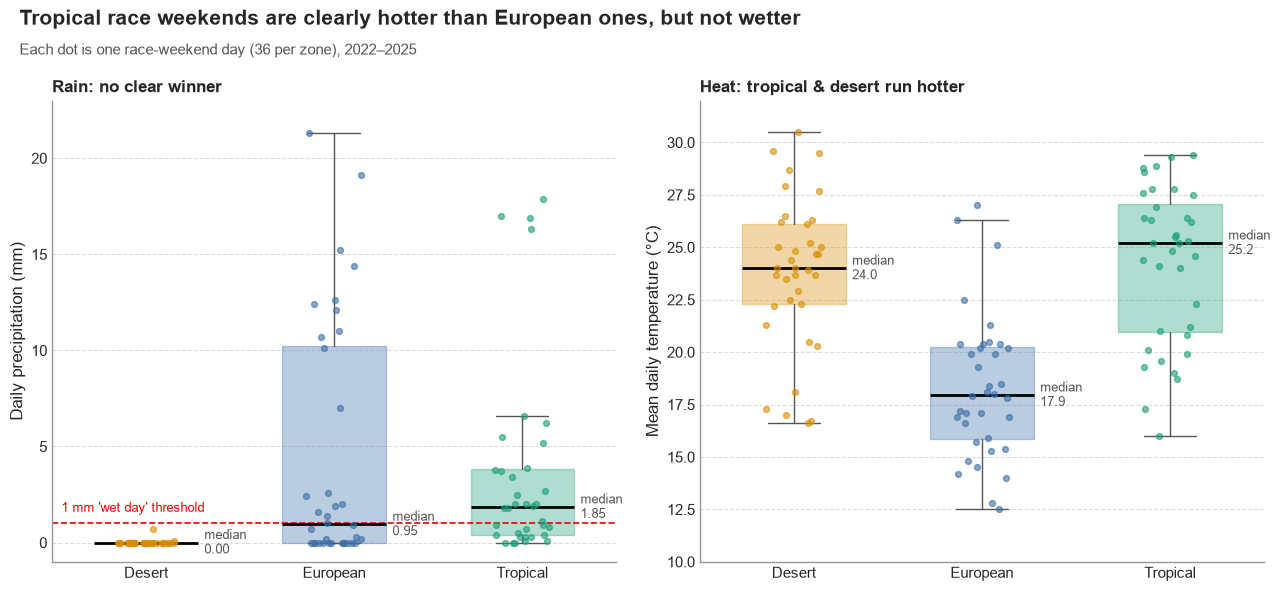

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
rng = np.random.default_rng(7)  # fixed seed so the jitter looks the same every run

panels = [("precip_mm", "Daily precipitation (mm)", "Rain: no clear winner", 2),
          ("temp_mean_c", "Mean daily temperature (°C)", "Heat: tropical & desert run hotter", 1)]

for ax, (col, ylabel, subtitle, dec) in zip(axes, panels):
    groups = [df.loc[df["climate_zone"] == z, col] for z in ZONES]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.55,
                    medianprops=dict(color="black", linewidth=2),
                    whiskerprops=dict(color=GREY), capprops=dict(color=GREY),
                    flierprops=dict(marker=""))  # hide fliers; the jittered points show every day
    for patch, zone in zip(bp["boxes"], ZONES):
        patch.set_facecolor(ZONE_COLORS[zone])
        patch.set_alpha(0.35)
        patch.set_edgecolor(ZONE_COLORS[zone])
    for i, (vals, zone) in enumerate(zip(groups, ZONES), start=1):
        x = i + rng.uniform(-0.15, 0.15, len(vals))
        ax.scatter(x, vals, color=ZONE_COLORS[zone], alpha=0.6, s=18, zorder=3)
        ax.text(i + 0.31, vals.median(), f"median\n{vals.median():.{dec}f}", va="center", fontsize=9, color=GREY)

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(ZONES)
    ax.set_ylabel(ylabel)
    ax.set_title(subtitle, fontsize=12, loc="left")
    clean_axes(ax)

axes[0].axhline(1.0, color=F1_RED, linestyle="--", linewidth=1.2)
axes[0].text(0.55, 1.6, "1 mm 'wet day' threshold", color=F1_RED, fontsize=9)
axes[0].set_ylim(-1, 23)
axes[1].set_ylim(10, 32)

fig.suptitle("Tropical race weekends are clearly hotter than European ones, but not wetter",
             fontsize=15, fontweight="bold", x=0.02, ha="left")
fig.text(0.02, 0.905, "Each dot is one race-weekend day (36 per zone), 2022–2025", fontsize=11, color=GREY)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 8. Explaining my design decisions

| What I changed | Why | How it helps the audience |
|---|---|---|
| **Style sheet** (`plt.style.use("seaborn-v0_8-whitegrid")`) plus shared font sizes | The default style looks unfinished, and its small text is hard to read on a laptop or projector | Gives all three figures one consistent, clean look, and the text is readable |
| **Larger figure sizes** (`figsize`) | The defaults were cramped, and annotations had no room | Leaves space for labels and annotations without overlap |
| **Consistent climate-zone colors and markers** (sand / blue / teal; square / circle / triangle) | Default colors are arbitrary and change from chart to chart | A reader learns the key once and it holds in every figure. Different marker shapes also mean the scatter still works in black-and-white or for color-blind readers |
| **F1 red only for reference lines** | I wanted one color that always means "pay attention here" | Readers' eyes go straight to the mean line and the wet-day threshold |
| **Transparency** (`alpha`) on points and boxes | Many points overlap, especially the zero-rain days | Overlapping points show up as darker areas instead of hiding each other |
| **Reference lines** (mean and median on the histogram; 1 mm threshold on the boxplot) | The gap between the mean and median is the clearest sign of skew | Readers can *see* how far the mean is pulled up by a few wet days |
| **Annotations** (wettest day, % of dry days, zone labels on the scatter) | The raw charts leave the reader to find the story on their own | The key findings sit right on the chart, so the figure works without the surrounding text |
| **Custom bins and ticks** (1 mm bins, ticks every 2 mm, °C and % tick labels) | Default bin edges were awkward decimals, and the axes had no units | Each bar has a clear meaning, and the units are visible on the axes themselves |
| **Axis limits** | Set to frame the data with some room for annotations | Removes empty space and keeps the scale the same across runs |
| **Removed top/right spines and softened the gridlines** | Heavy borders and grids add visual clutter | Puts the focus on the data |
| **Subplots** (rain and temperature boxplots side by side) | My hypothesis has two parts | Readers can compare the two claims directly, using the same colors and layout |
| **Jittered points over the boxplots** | With so many zero values, the boxes alone hid how the rain data was spread | Shows every day, including how flat the desert data is and how far the European downpours reach |
| **Descriptive, left-aligned titles that state the finding** | "Precipitation by climate zone" only names the variables | The title tells readers what the chart shows before they even read the axes |
| **`tight_layout()`** | Labels and suptitles were overlapping or getting cut off | Everything fits cleanly in the figure |

## Part 4: Statistical Analysis

### 9. Option A: comparing two groups with OLS

My hypothesis compares **tropical** and **European** circuits, so for this analysis I keep only those two groups
(72 days) and leave the desert circuits out. They were only a dry baseline, and including them would make the comparison
about "rain vs. no rain" instead of tropical vs. European.

- **Dependent variable (Y):** `precip_mm`, the daily precipitation
- **Independent variable (X):** `climate_zone`, either European or Tropical

I fit the model with `statsmodels.formula.api.ols`. Using `C(..., Treatment("European"))` makes **European** the reference group,
so:

- the **intercept** is the average daily precipitation at European circuits, and
- the **Tropical coefficient** is how much more (or less) rain tropical circuits get on average.

The markdown above was written with Claude to explain the following.

In [17]:
two_groups = df[df["climate_zone"].isin(["European", "Tropical"])].copy()
two_groups["climate_zone"] = two_groups["climate_zone"].cat.remove_unused_categories()

rain_model = smf.ols('precip_mm ~ C(climate_zone, Treatment("European"))', data=two_groups).fit()
print(rain_model.summary())

                            OLS Regression Results                            
Dep. Variable:              precip_mm   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                 -0.008
Method:                 Least Squares   F-statistic:                    0.4053
Date:                Sun, 15 Nov 2026   Prob (F-statistic):              0.526
Time:                        14:36:49   Log-Likelihood:                -227.41
No. Observations:                  72   AIC:                             458.8
Df Residuals:                      70   BIC:                             463.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------

In [18]:
def report(model, label, unit):
    term = [t for t in model.params.index if "Tropical" in t][0]
    lo, hi = model.conf_int().loc[term]
    print(f"{label}")
    print(f"  European average (intercept): {model.params['Intercept']:.2f} {unit}")
    print(f"  Tropical difference:          {model.params[term]:+.2f} {unit}  (95% CI {lo:+.2f} to {hi:+.2f})")
    print(f"  p-value:                      {model.pvalues[term]:.4f}")
    print(f"  R-squared:                    {model.rsquared:.3f}\n")


report(rain_model, "Daily precipitation", "mm")

Daily precipitation
  European average (intercept): 4.47 mm
  Tropical difference:          -0.87 mm  (95% CI -3.58 to +1.85)
  p-value:                      0.5264
  R-squared:                    0.006



**Interpreting the precipitation model:**

 The intercept (4.47 mm) is the average daily precipitation on European race weekends.
 The Tropical coefficient (−0.87 mm means tropical race-weekend days averaged slightly *less* rain than European
  ones. That's the opposite direction from what I predicted.
 The p-value (0.53) is far above 0.05, so the difference is not statistically significant. The 95% confidence interval
  (−3.58 to +1.85 mm) includes zero, which means "no difference" is entirely plausible.
 R² ≈ 0.006: climate zone explains less than 1% of the day-to-day variation in rainfall.

**The precipitation half of my hypothesis is not supported.** Based on this data, tropical race weekends are not
measurably wetter than European ones.

#### Testing the temperature half of the hypothesis

My hypothesis also predicted that tropical weekends would be hotter, so I fit a second model with the same structure,
using `temp_mean_c` as Y:

In [19]:
temp_model = smf.ols('temp_mean_c ~ C(climate_zone, Treatment("European"))', data=two_groups).fit()
report(temp_model, "Mean daily temperature", "°C")

Mean daily temperature
  European average (intercept): 18.31 °C
  Tropical difference:          +5.91 °C  (95% CI +4.23 to +7.59)
  p-value:                      0.0000
  R-squared:                    0.413



Interpreting the temperature model: European race-weekend days averaged 18.3 °C, and tropical days were 5.9 °C
warmer on average. The p-value is far below 0.001, and climate zone alone explains about 41% of the variation in
temperature (R² ≈ 0.41). The temperature half of my hypothesis is strongly supported.


Days within the same weekend aren't really independent. If it's stormy on Saturday, it's more likely to be stormy on Sunday.
To check that this isn't distorting the rain result, I added up the precipitation for each weekend (24 weekends) and refit the model:

In [20]:
weekends = (two_groups.groupby(["circuit", "season", "climate_zone"], observed=True, as_index=False)
                      .agg(weekend_precip_mm=("precip_mm", "sum")))
weekend_model = smf.ols('weekend_precip_mm ~ C(climate_zone, Treatment("European"))', data=weekends).fit()
report(weekend_model, "Total precipitation per race weekend (n = 24 weekends)", "mm")

print(weekends.groupby("climate_zone", observed=True)["weekend_precip_mm"].agg(["mean", "median"]).round(1))

Total precipitation per race weekend (n = 24 weekends)
  European average (intercept): 13.43 mm
  Tropical difference:          -2.60 mm  (95% CI -11.71 to +6.51)
  p-value:                      0.5601
  R-squared:                    0.016

              mean  median
climate_zone              
European      13.4    12.7
Tropical      10.8     6.0


At the weekend level, the result is the same. European weekends averaged about 13.4 mm of rain, tropical weekends about
10.8 mm, and the difference is not significant (p ≈ 0.56).

### What the statistical analysis reveals

The analysis separates the two halves of my hypothesis: tropical race weekends are significantly hotter than
European ones, but not significantly wetter. When rainfall is averaged out, European circuits (Spa in particular) are
just as likely to deliver a rain-soaked weekend as Singapore, Miami or São Paulo.



## Part 5: Conclusions and Reflection

### 10. Interpreting my findings

**What did I find?** Each of the different climates have a distinct look in terms of temperature and humidity as seen in the visualizations. European circuts are by far the coolest temperatures, while the tropical are both hot and humid. As for my hypothesis, I was correct in this assumption on temperature, but rain was a little different. European circuts have more total rain than the tropical ones, but the tropical circuts have more rainy days on average. 

**Limitations of the Data** The data from Open-Meteo is not specific to the circuts, the data is from the city nearest to the track. This could change the data due to some of the cities being rather large. The data is also based on daily averages which does not 100% accurately reflect the true race temperature if the race was at night. 

**What the data fals to capture** This data does not analyze how the weather impacts racing in anyway or how it shifts the race weekends. This is looking only at the weather from a statistical standpoint. 

**How did the stats shift from the visuals?** The rainfall on the visualizations was much more inconclusive than the stats would assume. This constants the temperature which was very clear in both stats and visuals. This would lead me to believe that the temperature would be more predictable based on climate than the rainfall. 

**In Summary** I found that the temperature followed my hypothesis of the tropical circuts being hotter than the European circuts, however, the rainfall prediction was found to be inconclusive due to the difference in total rain vs days with rain. I would now be able to predict confidently that the temperature at Singapore or Miami but I would need to also have rain covers ready at both the European track of Spa too. 